# Level 3 — Task 2: Votes Analysis

### Most & Least Voted Restaurants and the Link Between Votes and Ratings

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Which restaurants attract the most customer attention,
and do restaurants with more votes also earn higher ratings?

**Objectives:**
1. Identify the restaurants with the highest and lowest number of votes.
2. Analyze whether there is a correlation between the number of votes and the
   rating of a restaurant.

## 1. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [4]:
print("Missing Votes values:", df["Votes"].isna().sum())
print("Missing Aggregate rating values:", df["Aggregate rating"].isna().sum())
print("Votes range:", df["Votes"].min(), "to", f"{df['Votes'].max():,}")

zero_votes = df[df["Votes"] == 0]
unrated = (df["Aggregate rating"] == 0).sum()
print(f"Restaurants with 0 votes: {len(zero_votes):,} ({len(zero_votes) / len(df) * 100:.2f}%)")
print(f"Unrated restaurants (rating = 0): {unrated:,} ({unrated / len(df) * 100:.2f}%)")
print("Every restaurant with 0 votes is unrated:", (zero_votes["Aggregate rating"] == 0).all())

Missing Votes values: 0
Missing Aggregate rating values: 0
Votes range: 0 to 10,934
Restaurants with 0 votes: 1,094 (11.45%)
Unrated restaurants (rating = 0): 2,148 (22.49%)
Every restaurant with 0 votes is unrated: True


Both columns are fully populated. A rating of `0` means **"Not rated"**, and every
restaurant with 0 votes is unrated (a rating needs at least a few votes), so
unrated restaurants must be handled carefully in the correlation analysis
(Section 4).

## 3. Highest and Lowest Number of Votes

In [5]:
cols = ["Restaurant Name", "City", "Votes", "Aggregate rating", "Price range"]

top_voted = df.nlargest(10, "Votes")[cols].reset_index(drop=True)
top_voted.index = top_voted.index + 1
top_voted.index.name = "Rank"
top_voted

,Restaurant Name,City,Votes,Aggregate rating,Price range
Rank,,,,,
1,Toit,Bangalore,10934,4.8,4
2,Truffles,Bangalore,9667,4.7,2
3,Hauz Khas Social,New Delhi,7931,4.3,3
4,Peter Cat,Kolkata,7574,4.3,3
5,AB's - Absolute Barbecues,Bangalore,6907,4.6,3
6,Barbeque Nation,Kolkata,5966,4.9,3
7,Big Brewsky,Bangalore,5705,4.5,3
8,AB's - Absolute Barbecues,Hyderabad,5434,4.9,3
9,The Black Pearl,Bangalore,5385,4.1,3


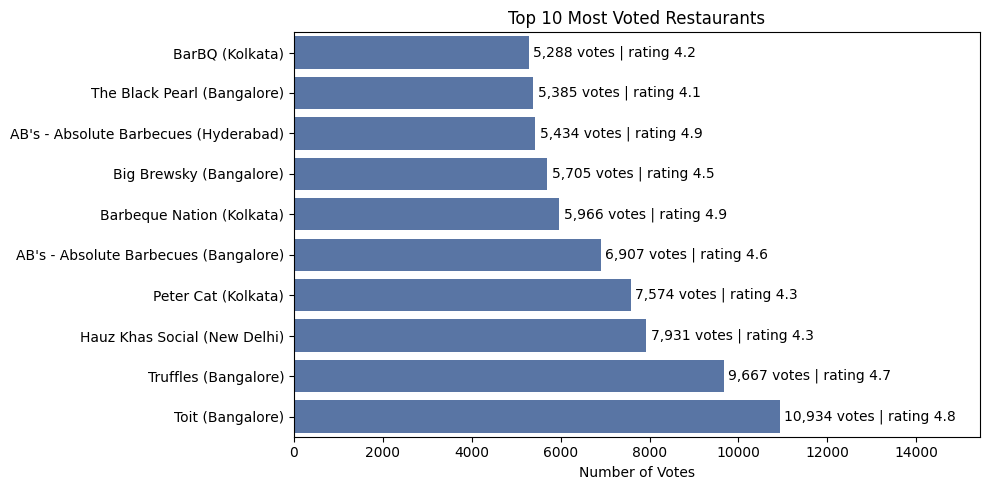

In [6]:
plot_top = top_voted.copy()
plot_top["Label"] = plot_top["Restaurant Name"] + " (" + plot_top["City"] + ")"
plot_top = plot_top.sort_values("Votes")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=plot_top["Votes"], y=plot_top["Label"], color="#4C72B0")
for i, (v, r) in enumerate(zip(plot_top["Votes"], plot_top["Aggregate rating"])):
    ax.text(v + 100, i, f"{v:,} votes | rating {r}", va="center")
plt.xlim(0, plot_top["Votes"].max() + 4500)
plt.title("Top 10 Most Voted Restaurants")
plt.xlabel("Number of Votes")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [7]:
total_votes = df["Votes"].sum()
print(f"Total votes in the dataset: {total_votes:,}")
print(f"Top 10 restaurants hold {top_voted['Votes'].sum():,} votes ({top_voted['Votes'].sum() / total_votes * 100:.2f}% of all votes)")
print(f"Most voted restaurant: {top_voted.iloc[0]['Restaurant Name']} ({top_voted.iloc[0]['City']}) with {top_voted.iloc[0]['Votes']:,} votes")

heavy = df[df["Votes"] >= 1000]
print(f"Restaurants with 1,000+ votes: {len(heavy)} ({len(heavy) / len(df) * 100:.2f}% of listings) hold {heavy['Votes'].sum() / total_votes * 100:.2f}% of all votes")

Total votes in the dataset: 1,498,645
Top 10 restaurants hold 70,791 votes (4.72% of all votes)
Most voted restaurant: Toit (Bangalore) with 10,934 votes
Restaurants with 1,000+ votes: 296 (3.10% of listings) hold 39.14% of all votes


### Lowest number of votes

The lowest possible value is 0 votes, and **many restaurants share it**, so there
is no single "lowest" restaurant. The group with 0 votes is summarised instead.

In [8]:
print(f"Restaurants with the lowest vote count (0): {len(zero_votes):,} ({len(zero_votes) / len(df) * 100:.2f}% of all listings)")
print("\nWhere are they?")
zero_votes["City"].value_counts().head(5)

Restaurants with the lowest vote count (0): 1,094 (11.45% of all listings)

Where are they?


City
New Delhi     715
Noida         191
Gurgaon       129
Faridabad      57
S��o Paulo      1
Name: count, dtype: int64

In [9]:
rated_df = df[df["Aggregate rating"] > 0]

min_rated_votes = rated_df["Votes"].min()
lowest_rated = rated_df[rated_df["Votes"] == min_rated_votes]
print(f"Lowest vote count among rated restaurants: {min_rated_votes} votes ({len(lowest_rated)} restaurants tied)")
print(f"Their average rating: {lowest_rated['Aggregate rating'].mean():.2f} (range {lowest_rated['Aggregate rating'].min()} to {lowest_rated['Aggregate rating'].max()})")
print("\nTop cities:")
print(lowest_rated["City"].value_counts().head(4))
lowest_rated[cols].head(8)

Lowest vote count among rated restaurants: 4 votes (207 restaurants tied)
Their average rating: 2.94 (range 2.4 to 3.2)

Top cities:
City
New Delhi    137
Gurgaon       29
Noida         29
Faridabad     12
Name: count, dtype: int64


,Restaurant Name,City,Votes,Aggregate rating,Price range
865,Desire Foods,Faridabad,4,2.9,1
870,Snax Points,Faridabad,4,3.0,1
875,Cafe And More,Faridabad,4,2.9,1
962,Baskin Robbins,Faridabad,4,2.9,1
965,Hungrill,Faridabad,4,3.0,2
1013,Snacks Bar,Faridabad,4,2.9,1
1046,Cravings,Faridabad,4,3.0,2
1054,Punjabi Culture,Faridabad,4,2.9,2


In [10]:
vote_dist = pd.DataFrame({
    "Statistic": ["Mean", "Median", "75th percentile", "90th percentile", "Maximum"],
    "Votes": [df["Votes"].mean(), df["Votes"].median(), df["Votes"].quantile(0.75),
              df["Votes"].quantile(0.90), df["Votes"].max()],
}).round(1)
vote_dist

,Statistic,Votes
0,Mean,156.9
1,Median,31.0
2,75th percentile,131.0
3,90th percentile,379.0
4,Maximum,10934.0


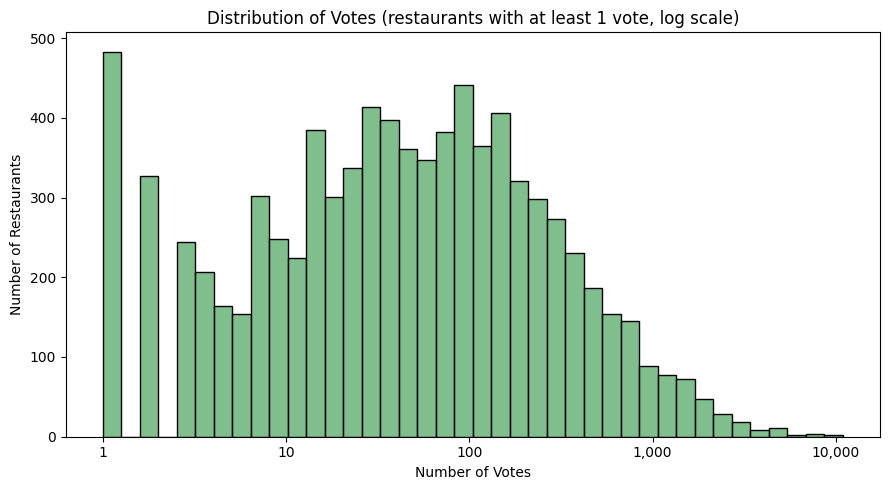

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(np.log10(df.loc[df["Votes"] > 0, "Votes"]), bins=40, color="#55A868")
plt.xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1,000", "10,000"])
plt.title("Distribution of Votes (restaurants with at least 1 vote, log scale)")
plt.xlabel("Number of Votes")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

## 4. Correlation Between Votes and Ratings

Unrated restaurants always have 0 votes **and** a rating of 0, which would create
an artificial link between the two columns. The fair analysis therefore uses
**rated restaurants only**. Two measures are used:

- **Pearson** measures a straight-line relationship, which is distorted by a few
  restaurants with thousands of votes.
- **Spearman** (rank-based) and Pearson on **log(votes)** handle this skew better.

In [12]:
def votes_rating_corr(data):
    pearson = data[["Votes", "Aggregate rating"]].corr().iloc[0, 1]
    spearman = data[["Votes", "Aggregate rating"]].corr(method="spearman").iloc[0, 1]
    log_pearson = np.corrcoef(np.log10(data["Votes"] + 1), data["Aggregate rating"])[0, 1]
    return pearson, spearman, log_pearson

rows = []
for label, data in [("All restaurants (includes unrated)", df), ("Rated restaurants only", rated_df)]:
    p, s, lp = votes_rating_corr(data)
    rows.append({"Group": label, "Restaurants": len(data), "Pearson": round(p, 3),
                 "Spearman": round(s, 3), "Pearson (log votes)": round(lp, 3)})
corr_table = pd.DataFrame(rows)
corr_table

,Group,Restaurants,Pearson,Spearman,Pearson (log votes)
0,All restaurants (includes unrated),9551,0.314,0.846,0.848
1,Rated restaurants only,7403,0.409,0.682,0.649


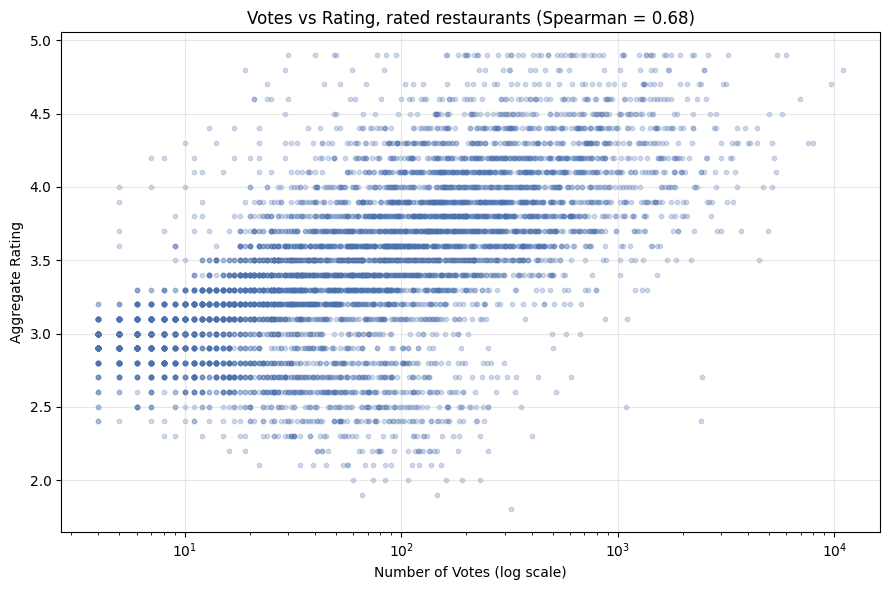

In [13]:
rated_p, rated_s, rated_lp = votes_rating_corr(rated_df)

plt.figure(figsize=(9, 6))
plt.scatter(rated_df["Votes"], rated_df["Aggregate rating"], s=10, alpha=0.25, color="#4C72B0")
plt.xscale("log")
plt.title(f"Votes vs Rating, rated restaurants (Spearman = {rated_s:.2f})")
plt.xlabel("Number of Votes (log scale)")
plt.ylabel("Aggregate Rating")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Average rating by vote band

In [14]:
bands = pd.cut(rated_df["Votes"], bins=[-1, 10, 50, 100, 500, 1000, 20000],
               labels=["0-10", "11-50", "51-100", "101-500", "501-1000", "1000+"])
band_table = (
    rated_df.groupby(bands, observed=True)["Aggregate rating"]
    .agg(Restaurants="count", Avg_Rating="mean", Median_Rating="median")
    .round(2)
)
band_table.index.name = "Vote Band"
band_table

,Restaurants,Avg_Rating,Median_Rating
Vote Band,,,
0-10,1075,2.98,3.0
11-50,2354,3.19,3.2
51-100,1169,3.41,3.5
101-500,2100,3.74,3.8
501-1000,409,4.08,4.1
1000+,296,4.20,4.2


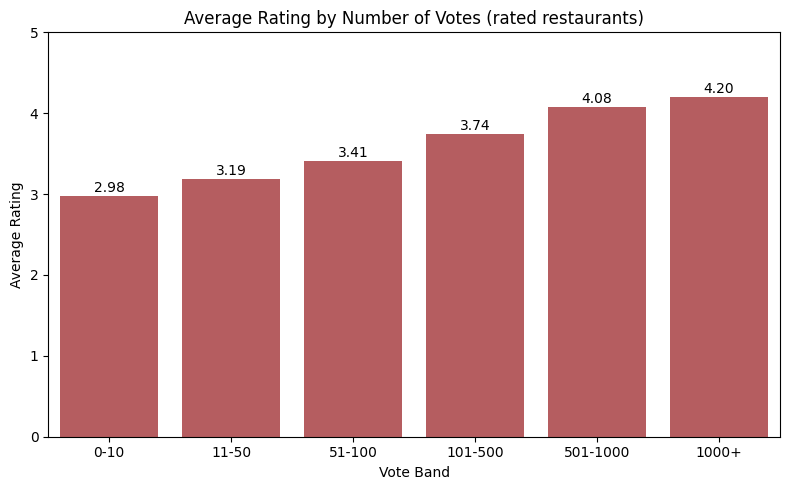

In [15]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=band_table.index.astype(str), y=band_table["Avg_Rating"], color="#C44E52")
for i, v in enumerate(band_table["Avg_Rating"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.ylim(0, 5)
plt.title("Average Rating by Number of Votes (rated restaurants)")
plt.xlabel("Vote Band")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

### Robustness check: India vs outside India

In [16]:
is_india = rated_df["Currency"].str.contains("Indian")

rows = []
for label, data in [("India", rated_df[is_india]), ("Outside India", rated_df[~is_india])]:
    p, s, lp = votes_rating_corr(data)
    rows.append({"Group": label, "Restaurants": len(data), "Pearson": round(p, 3),
                 "Spearman": round(s, 3), "Pearson (log votes)": round(lp, 3)})
pd.DataFrame(rows)

,Group,Restaurants,Pearson,Spearman,Pearson (log votes)
0,India,6513,0.396,0.651,0.624
1,Outside India,890,0.451,0.530,0.515


## 5. Final Results

In [17]:
task_result = pd.DataFrame({
    "Question": [
        "Most voted restaurant",
        "Its number of votes",
        "Lowest number of votes",
        "Restaurants with that lowest vote count",
        "Lowest vote count among rated restaurants",
        "Correlation votes vs rating (rated only, Spearman)",
        "Correlation votes vs rating (rated only, log votes)",
    ],
    "Answer": [
        f"{top_voted.iloc[0]['Restaurant Name']} ({top_voted.iloc[0]['City']})",
        f"{top_voted.iloc[0]['Votes']:,}",
        "0 votes",
        f"{len(zero_votes):,} ({len(zero_votes) / len(df) * 100:.2f}% of listings)",
        f"{min_rated_votes} votes ({len(lowest_rated)} restaurants)",
        f"{rated_s:.2f}",
        f"{rated_lp:.2f}",
    ],
})
task_result

,Question,Answer
0,Most voted restaurant,Toit (Bangalore)
1,Its number of votes,"10,934"
2,Lowest number of votes,0 votes
3,Restaurants with that lowest vote count,"1,094 (11.45% of listings)"
4,Lowest vote count among rated restaurants,4 votes (207 restaurants)
5,"Correlation votes vs rating (rated only, Spear...",0.68
6,"Correlation votes vs rating (rated only, log v...",0.65


## 6. Validation

In [18]:
print("Rated + unrated = total:", len(rated_df) + unrated == len(df))
print("Zero-vote restaurants are all unrated:", (zero_votes["Aggregate rating"] == 0).all())
print("Vote bands cover all rated restaurants:", band_table["Restaurants"].sum() == len(rated_df))
print("Top 10 table has 10 rows:", len(top_voted) == 10)

Rated + unrated = total: True
Zero-vote restaurants are all unrated: True
Vote bands cover all rated restaurants: True
Top 10 table has 10 rows: True


### Business Insights

**Most voted restaurants**

- **Toit (Bangalore) is the most voted restaurant with 10,934 votes** and a
  rating of 4.8, followed by Truffles (9,667 votes, 4.7), Hauz Khas Social
  (7,931, 4.3), Peter Cat in Kolkata (7,574, 4.3) and AB's - Absolute Barbecues
  in Bangalore (6,907, 4.6).
- **All of the top 10 are in India:** Bangalore has 5, Kolkata 3, and New Delhi
  and Hyderabad 1 each. All are rated 4.1 or higher (average 4.53), and 7 of the
  10 are in price range 3.
- **Attention is highly concentrated.** The top 10 alone hold 70,791 of the
  1,498,645 votes (4.72%), and the 296 restaurants with 1,000 or more votes (just
  3.10% of listings) hold 39.14% of all votes. The average restaurant has 156.9
  votes but the median is only 31, so a typical restaurant gets little attention.

**Least voted restaurants**

- **1,094 restaurants (11.45%) have 0 votes, the lowest possible value, so there
  is no single "least voted" restaurant.** All of them are unrated, and almost
  all are in the Delhi NCR: New Delhi 715, Noida 191, Gurgaon 129 and Faridabad
  57.
- **Among rated restaurants the minimum is 4 votes (207 restaurants tied).** Their
  ratings are low and narrow (2.4 to 3.2, average 2.94), and 137 of them are in
  New Delhi.

**Votes vs ratings**

- **More votes go with higher ratings, and the link is fairly strong.** For rated
  restaurants the rank correlation (Spearman) is **0.68** and the correlation of
  log(votes) with rating is **0.65**. The plain Pearson value (0.41) is lower
  only because a few restaurants with thousands of votes distort it.
- **Including unrated restaurants would overstate the link** (Spearman 0.85),
  because unrated restaurants have 0 votes and a rating of 0 by definition.
- **The pattern is steady across vote levels.** Average rating rises from 2.98
  for restaurants with up to 10 votes, to 3.19 (11-50 votes), 3.41 (51-100),
  3.74 (101-500), 4.08 (501-1,000) and 4.20 (more than 1,000). Of restaurants
  with over 1,000 votes, 72.64% are rated 4.0 or higher.
- **It holds both inside and outside India:** Spearman 0.65 for India and 0.53
  for the rest of the world.
- **It is not a rule.** Some restaurants with over 1,000 votes are rated as low
  as 2.4, so heavy voting does not guarantee a high rating.

**Caution**

- A correlation shows association, not cause. Good restaurants may attract more
  votes, and popular restaurants may also collect more votes simply by being
  well known; the data cannot separate the two.
- Ratings based on very few votes are less reliable, which may exaggerate the
  gap at the low end.
- The dataset has no dates, so a restaurant's age (how long it has been
  collecting votes) cannot be taken into account.
- 2,148 unrated restaurants are excluded from the correlation. The dataset is
  also a sample (about 20 listings for most cities) and India-heavy, so results
  mainly describe the Indian market.